# Introduction

Do checkout the THEORY Notebook:

https://www.kaggle.com/code/aryashah2k/introduction-to-it-ops-and-ai-theory

FAQ Recommendation For HelpDesk:

https://www.kaggle.com/code/aryashah2k/faq-recommendation-for-helpdesk

Incident Root Cause Analysis:

https://www.kaggle.com/code/aryashah2k/incident-root-cause-analysis

All Notebooks are under the Code Section of the dataset:

https://www.kaggle.com/datasets/aryashah2k/datasets-in-it-ops-applied-ai

### Time Series Forecasting

Let's demonstrate how to forecast time series data for IT Ops use cases. 

### What is a time series? 

A time series is a series of data points indexed in time order. It is a sequence of samples taken at successfully, equally spaced points in time. For example, this may include daily closing stock prices, hourly peak concurrent users in a website and total emails every minute in an email server. 

Time series data may be a steady sequence or may exhibit multiple trends. These trends can be cyclic, growth or seasonal. 

Examples of cyclic trends include hourly concurrent users in a website. Typically, the peak is much higher during midday than during night. Seasonal trends include higher daily travelers during holiday seasons. Trying to predict time series data for the future is a unique problem, because the model should account for the cyclic, growth and seasonal trends that are usually seen in time series data. 

### What is service load forecasting? 

A service in IT ops is any service that provides a specific function. Examples include websites, databases, APIs, et cetera. Each of these services need to be provided resources to handle the expected volumes of data. Providing too many resources means waste of money, providing too few resources would result in service degradation and failure. Service load forecasting predicts expected future workload by time. It plays a key role in creating the right capacity to handle these loads. The load pattern on any service is usually a time series, and the load varies based on the day of the week and time of the day. Typical corporate services have higher loads during midday and lower loads during nights and weekends. Time series forecasting involves predicting future values by time, based on previously observed values, There are multiple use cases for time series forecasting in IT ops. 

This includes website request loads, storage usage for databases, transaction loads on business services, et cetera. In this chapter, we will predict the future time series values for website request loads.

### Revision : Recurrent Neural Networks(RNN) & Long Short Term Memory(LSTM)

Let's review the recurrent neural networks, or RNN, and one of its popular implementations, called long short-term memory networks, or LSTM. 

### What is RNN? 

RNN is a class of artificial neural networks that models a temporal sequence. A time series is a type of temporal sequence with samples taken at equal points in time. RNNs use a sequence model concept where the predicted value of a sample at any given point in time is dependent upon the feature variables at that point in time, as well as adjoining values. RNN has become popular in applications that involve temporal sequences, like natural language processing, speech recognition, and time series forecasting. 

### Long short-term memory networks

LSTM in short, is a special kind of RNN that has the ability to selectively memorize past behavior to predict current behavior. In general, it does not provide the same weight to all samples in the recent past, but has selective logic that ensures that only significant samples from the past are retained in memory to predict future outcomes. LSTM has been very popular for predicting temporal sequences, like natural language, and has been known to generate accurate models that solve a number of corner cases too.

### Preparing The Sequence Data

Let's explore and prepare the time series data for deep learning. We want to predict the service request loads for the future, and we will use the service request loads in the past as training data.

Each record contains the total request for a given hour. The file contains continuous hourly sample points for a period of five weeks.

First, we load up the CSV containing the time series and explore its content. There is only one column containing the request. This is both the feature and the target variable for our machine learning. We are using the past request loads to predict the future request loads.

Next, let's plot the data to understand the patterns in the data. We start with the first day, which is 24 data points. Then we do the same pattern for the first weeks, which is 168 data points. Finally, we do this for all the five weeks. 

For the day, we see that it looks like a pyramid with the highest load during the middle of the day, and the night having lower loads. When we look at the weekly pattern, we see that the daily trend repeats for every day, we see seven pyramids. We also notice that the last two pyramids which represent Saturday and Sunday are slightly lower. So, there is a daily trend and a weekly trend here. Finally, when we look at all the five weeks, we see the weekly pattern repeating. But we also see a slight increase in the overall volume towards the last week. This is the growth trend. 

To prepare the data for deep learning, we first need to scale the data to a standard scale. We use the standard scaler in Scikit-learn for this purpose. This creates data points with a mean of zero. We then print the values before and after scaling. Next, we need to split the training and testing data sets. Unlike other machine learning use cases where we can randomly split the input set into training and testing, we need to split sequentially in RNN. So, we set the training data to the first four weeks of the data set and testing to be the last week. A key hyper-parameter for this model is the lookback. In order to predict a given data point in RNN, we need to provide the last n data points. This is indicated by the lookback period. We set this lookback period to be a week. We then split the scale request sequentially to training and test data sets. 

In order to predict each of the test samples, we need to provide a lookback of the previous week's data. So, when we split the test data set, we can provide it an additional week of lookback.

We see that the request range has gone from one to 488 to a normal range of minus 2.2 to plus 2.2 due to scaling. We also see the shape of the training and test data sets. Training set has four weeks of data and test set has two weeks of data including the lookback for a week.

In [1]:
# The data represents hourly total service requests for 5 weeks, starting with monday.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(1)

#Load the sequence data from CSV
requests = pd.read_csv('../input/datasets-in-it-ops-applied-ai/requests_every_hour.csv',header=0)

#Review loaded data
print(requests.dtypes)
requests.head()


Requests    int64
dtype: object


,Requests
0,100
1,113
2,162
3,186
4,228


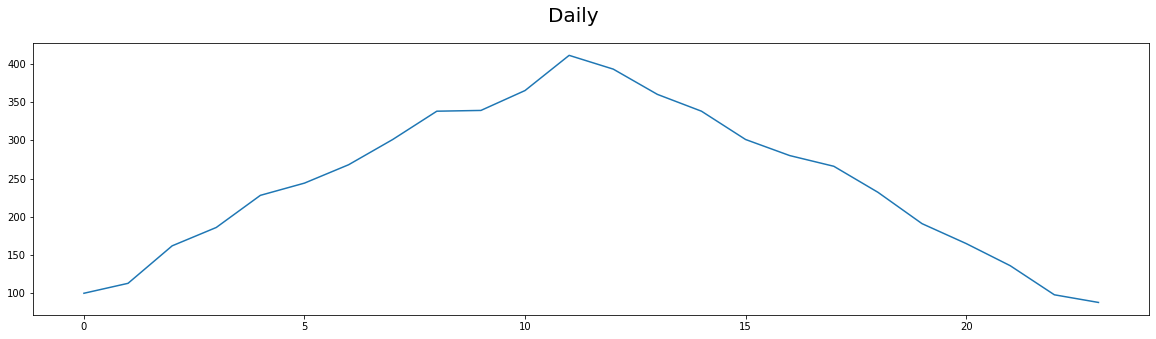

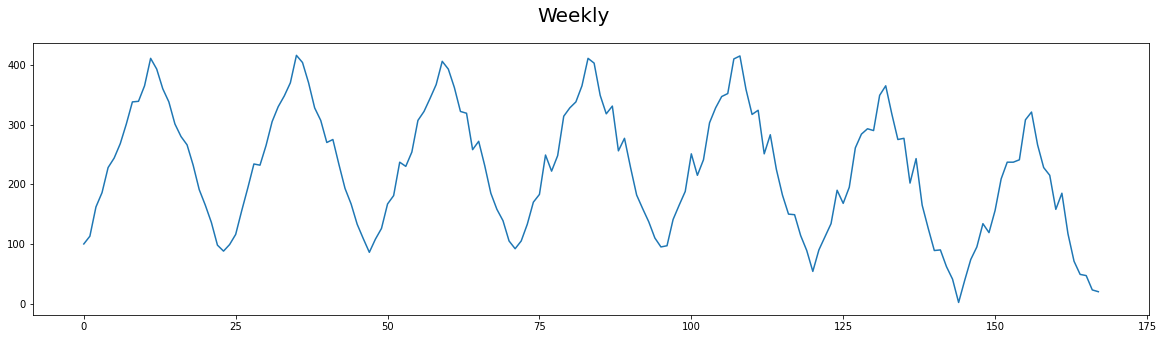

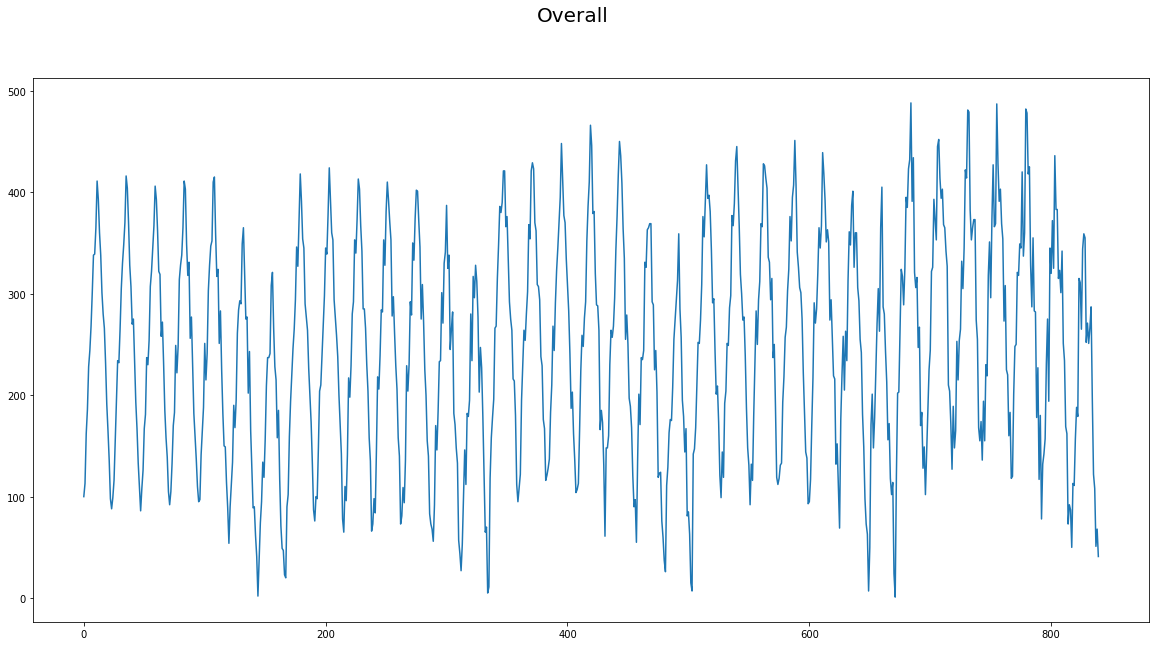

In [2]:
#Plot the data loaded to visualize trends

#daily
plt.figure(figsize=(20,5)).suptitle("Daily", fontsize=20)
plt.plot(requests.head(24))
plt.show()

#weekly
plt.figure(figsize=(20,5)).suptitle("Weekly", fontsize=20)
plt.plot(requests.head(168))
plt.show()

#all
plt.figure(figsize=(20,10)).suptitle("Overall", fontsize=20)
plt.plot(requests)
plt.show()

In [3]:
from sklearn.preprocessing import StandardScaler

#Scale the data
print("Request Range before scaling : " , 
          min(requests.Requests),
          max(requests.Requests))

scaler = StandardScaler()
scaled_requests=scaler.fit_transform(requests)
print("Request Range after scaling : " , 
          min(scaled_requests),
          max(scaled_requests))

#Training data has to be sequencial - first 4 weeks
train_size = 24 * 7 * 4

#Number of samples to lookback for each sample
lookback=24 * 7

#Separate training and test data
train_requests = scaled_requests[0:train_size,:]

#Add an additional week for lookback.
test_requests = scaled_requests[train_size-lookback:,:]

print("\n Shape of Train, Test : ",
      train_requests.shape, test_requests.shape)

Request Range before scaling :  1 488
Request Range after scaling :  [-2.28221282] [2.23748868]

 Shape of Train, Test :  (672, 1) (336, 1)


### Building LSTM Model With Keras

Now, we will build an LSTM models with Keras to predict a time series. To predict each data point, we need to provide a lookback of data points. For this, we need to create a data set that associates each data point with the previous 168 data points, which is a week's worth of lookback. 

We do so using the Create RNN Dataset function. This function takes as input, a data set and a lookback period. It then creates the feature Vector X, and the prediction Y. X contains the previous 168 data points for the corresponding Y. This means that if we pass four weeks of data, we will only get three weeks of X and Y, since the first week will be lost in the lookback. 

We iterate over the data set, we create X using the last 168 lookback points and Y being the current point. We return the final array then. We use this method to create X and Y arrays for the training data set. Then we reshape X as a three dimensional array for use with LSTM. Finally, we print samples.

We see that X now has 503 data points, which is three weeks worth of data, each data point as a look back of 168 values. Now let's get to building the model. We create a sequential model in Keras. Then we add an LSTM layer of 256 units. Finally, we add a dense layer that outputs one value, which is the predicted value of the node. We compile the model with Adam Optimizer, we use the mean squared error as the loss function. We also print the model generated. We then fit the model with 5 epochs and a batch size of one.

As we can see, the loss reduces quickly to around 0.5.

In [4]:
#Prepare RNN Dataset. 
#Each data point (X) is linked to the previous data points of size=lookback
#The predicted value (Y) is the next point

def create_rnn_dataset(data, lookback=1):
    
    data_x, data_y = [], []
    for i in range(len(data)- lookback -1):
            #All points from this point, looking backwards upto lookback
            a = data[i:(i+ lookback), 0]
            data_x.append(a)
            #The next point
            data_y.append(data[i + lookback, 0])
    return np.array(data_x), np.array(data_y)

#Create X and Y for training
train_req_x, train_req_y = create_rnn_dataset(train_requests,lookback)

#Reshape for use with LSTM
train_req_x = np.reshape(train_req_x, 
                         (train_req_x.shape[0],1, train_req_x.shape[1]))

print("Shapes of X, Y: ",train_req_x.shape, train_req_y.shape)

Shapes of X, Y:  (503, 1, 168) (503,)


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense
import tensorflow as tf

tf.random.set_seed(3)

#Create a Keras Model
ts_model=Sequential()
#Add LSTM
ts_model.add(LSTM(256, input_shape=(1,lookback)))
ts_model.add(Dense(1))

#Compile with Adam Optimizer. Optimize for minimum mean square error
ts_model.compile(loss="mean_squared_error",
                 optimizer="adam",
                 metrics=["mse"])

#Print model summary
ts_model.summary()

#Train the model
ts_model.fit(train_req_x, train_req_y, 
             epochs=5, batch_size=1, verbose=1)

2022-06-12 04:14:30.385799: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lstm (LSTM)                  (None, 256)               435200    
_________________________________________________________________
dense (Dense)                (None, 1)                 257       
Total params: 435,457
Trainable params: 435,457
Non-trainable params: 0
_________________________________________________________________
Epoch 1/5


2022-06-12 04:14:30.821996: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


503/503 [==============================] - 4s 4ms/step - loss: 0.1530 - mse: 0.1530
Epoch 2/5
503/503 [==============================] - 2s 3ms/step - loss: 0.0762 - mse: 0.0762
Epoch 3/5
503/503 [==============================] - 2s 3ms/step - loss: 0.0666 - mse: 0.0666
Epoch 4/5
503/503 [==============================] - 2s 3ms/step - loss: 0.0493 - mse: 0.0493
Epoch 5/5
503/503 [==============================] - 2s 4ms/step - loss: 0.0527 - mse: 0.0527


### Testing The Model

We will test the model we built earlier using the test data set. Please note that for predicting each data point with the test data set, we have the previous 168 data points from actual data. 

In order to test, we first process the test data set with the same create_rnn_dataset function to associate each data point with the previous 168 data points. Then we use the evaluate function to evaluate the model. For comparison sake, we will predict for both the training data set and the test data set. In order to review the results, we will need to do an inverse transform to convert them from the standard scale to the same scale as the original values. 

Now, let's plot the predictions obtained to see how they match up against the original data. The total size of the plot would be the combined size of the predictions on training and testing. First, we get the original data from the data frame and convert it to the same shape as that of the predictions. We then create an original plot of the size equal to the total number of predictions. We copy the value starting from the 168 point in the original data into this block. This is because there are no predictions for the first 167 points, as they are only used as lookback. 

Next, we create a training plot in a similar fashion, but copying the data only to match the same equal and data points in the original, which is the second, third and fourth weeks. 

Next, we create a test plot by matching those with the equal end points and the original, which is the fifth week only. Let's execute this code and review the combined results. In this plot, we see the blue line, which is the original data. The orange line is for predictions on the training data set for the second, third and fourth weeks. The green line is a prediction for the fifth week, which is on the test data set. As we can see, the predictions closely match the trends seen in the original data. This is a fairly good forecast.

In [6]:
#Preprocess the test dataset, the same way training set is processed
test_req_x, test_req_y = create_rnn_dataset(test_requests,lookback)
test_req_x = np.reshape(test_req_x, 
                         (test_req_x.shape[0],1, test_req_x.shape[1]))

#Evaluate the model
ts_model.evaluate(test_req_x, test_req_y, verbose=1)

#Predict for the training dataset
predict_on_train= ts_model.predict(train_req_x)
#Predict on the test dataset
predict_on_test = ts_model.predict(test_req_x)

#Inverse the scaling to view results
predict_on_train = scaler.inverse_transform(predict_on_train)
predict_on_test = scaler.inverse_transform(predict_on_test)

6/6 [==============================] - 1s 2ms/step - loss: 0.1552 - mse: 0.1552


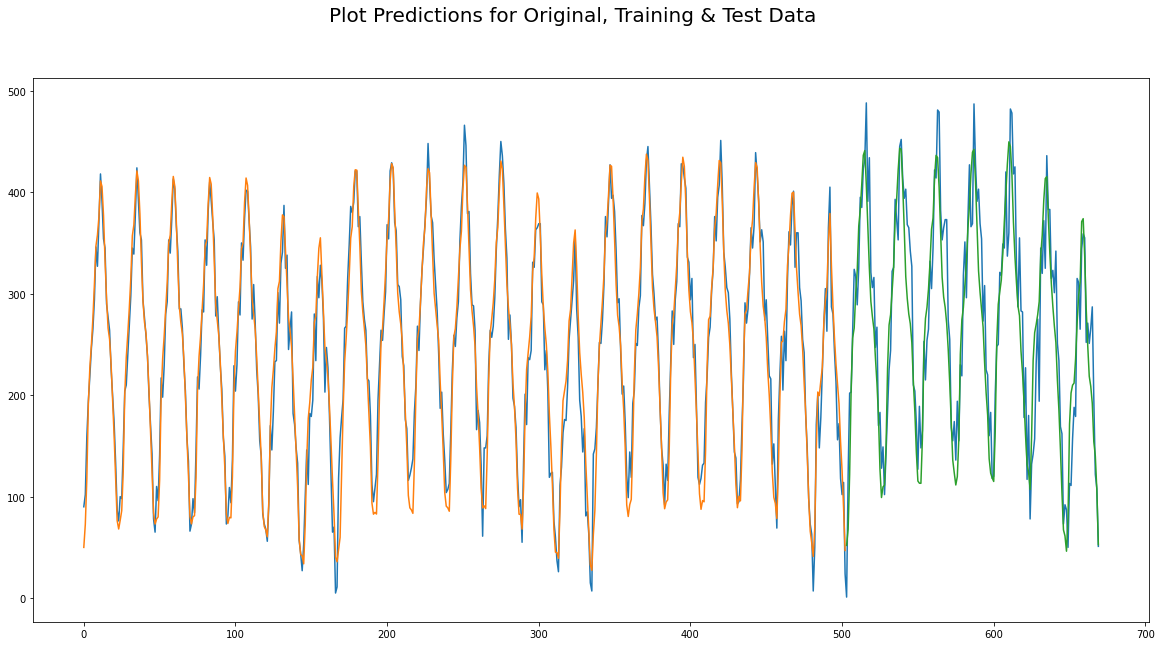

In [7]:
#Plot the predictions

#Total size of plot
total_size = len(predict_on_train) + len(predict_on_test)

#Plot original data
orig_data=requests.Requests.to_numpy()
orig_data=orig_data.reshape(len(orig_data),1)

#Create a plot for original data
orig_plot = np.empty((total_size,1))
orig_plot[:, :] = np.nan
orig_plot[0:total_size, :] = orig_data[lookback:-2,]

#Create a plot for predictions on training
predict_train_plot = np.empty((total_size,1))
predict_train_plot[:, :] = np.nan
predict_train_plot[0:len(predict_on_train), :] = predict_on_train

#Create a plot for predictions on testing
predict_test_plot = np.empty((total_size,1))
predict_test_plot[:, :] = np.nan
predict_test_plot[len(predict_on_train):total_size, :] = predict_on_test

#Plot the graphs
plt.figure(figsize=(20,10)).suptitle("Plot Predictions for Original, Training & Test Data", fontsize=20)
plt.plot(orig_plot)
plt.plot(predict_train_plot)
plt.plot(predict_test_plot)
plt.show()

### Forecasting Future Service Loads

We will forecast future service loads for a full week using the model we built. One important factor to consider here is this. In the case of the test data we used, each data point we wanted to predict, we had 168 lookback data points from the actual data. 

But if we want to predict in the future, we can only predict the first point, since only that point has a complete lookback from actual data. If we reduce our lookback size, it will impact the overall accuracy of our predictions. 

### How do we predict data points beyond the first point? 

To do this, we iteratively predict each data point and then add that predicted point into the lookback dataset for the next point. For example, to predict a new forecast point P1, we use the last 168 points from the test dataset. Then to predict the next point, which is P2, we use a lookback that contains P1 and the last 167 points from the test dataset. In this iterative process, we use the predicted values in the lookback for the next value.

We first use the test dataset that we have and flatten it. We store that as current book, which will be the input dataset. We then set the predict for variable to the next 168 points, which is a week into the future. We then iterate over the predict for a number of times. We predict the first data point by using the test data as input. We take the predicted value and then append it to the current input variable. 

In the next iteration, we use the last 168 data points, which includes the first predicted value. This way, we predict each data point and use it as input to the next data point. By continuing this process, we predict for the entire week. We then copy over the predicted values and do an inverse transform to convert it to the actual scale. Let's review the first five predicted data points. 

Next, let's plot this value to see if we see the same kind of trends. Similar to how we did it before, we create a chart showing the training weeks, which are weeks two, three, and four, the test week, which is five, and the future week, which is six.

The predictions on the training weeks are shown in blue, the test week in orange, and the future week in green. As we can see, the prediction for the future week largely follows the cyclical patterns for the days and also the seasonal pattern for the week. It also keeps the growth trend.

| Predict | Lookback           |
|:--------------|:-------------------------|
| P1      | T168 - T1          |
| P2      | P1, T168 - T2      |
| P3      | P2 - P1, T168 - T3 |
| P4      | P3 -P1, T168 - T4  |
| P5      | P4 - P1, T168 - T5|

In [8]:
#Use last part of the training data as the initial lookback
curr_input= test_req_x[-1,:].flatten()

#Predict for the next week
predict_for = 24 * 7

for i in range(predict_for):
    
    #Take the last lookback no. of samples as X
    this_input=curr_input[-lookback:]
    #Create the input
    this_input=this_input.reshape((1,1,lookback))
    #Predict for the next point
    this_prediction=ts_model.predict(this_input)

    #Add the current prediction to the input
    curr_input = np.append(curr_input,this_prediction.flatten())

#Extract the last predict_for part of curr_input, which contains all the new predictions
predict_on_future=np.reshape(np.array(curr_input[-predict_for:]),(predict_for,1))

# #Inverse to view results
predict_on_future=scaler.inverse_transform(predict_on_future)

print(predict_on_future[:5])

[[ 52.72606006]
 [ 54.4535907 ]
 [ 70.10666862]
 [ 88.45015342]
 [150.52303244]]


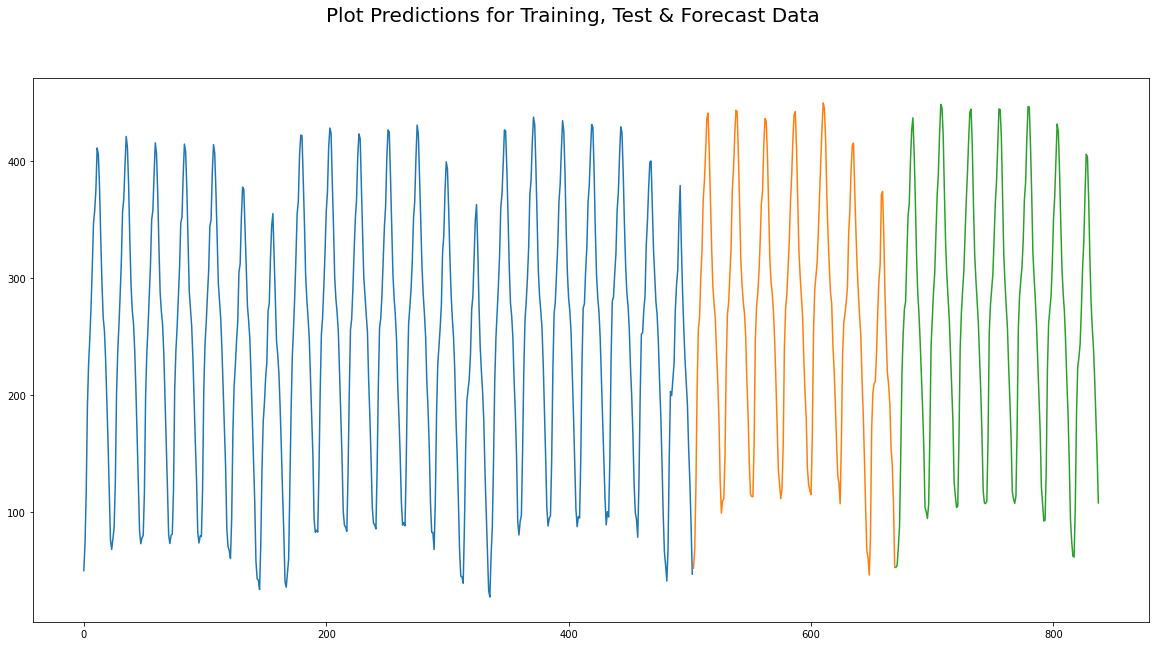

In [9]:
#Plot the training data with the forecast data
total_size = len(predict_on_train) + len(predict_on_test) + len(predict_on_future)

#Setup training chart
predict_train_plot = np.empty((total_size,1))
predict_train_plot[:, :] = np.nan
predict_train_plot[0:len(predict_on_train), :] = predict_on_train

#Setup test chart
predict_test_plot = np.empty((total_size,1))
predict_test_plot[:, :] = np.nan
predict_test_plot[len(predict_on_train):len(predict_on_train)+len(predict_on_test), :] = predict_on_test

#Setup future forecast chart
predict_future_plot = np.empty((total_size,1))
predict_future_plot[:, :] = np.nan
predict_future_plot[len(predict_on_train)+len(predict_on_test):total_size, :] = predict_on_future

plt.figure(figsize=(20,10)).suptitle("Plot Predictions for Training, Test & Forecast Data", fontsize=20)
plt.plot(predict_train_plot)
plt.plot(predict_test_plot)
plt.plot(predict_future_plot)
plt.show()

# Conclusion

With this we conclude the notebook after successfully applying AI to a use-case of Service Load Forecasting in IT Ops.

⭐ Have a great day! ⭐

📙📙📙📙📙📙📙📙📙📙 Happy Learning! 📙📙📙📙📙📙📙📙📙📙